# Shakespeare Next Word Prediction using LSTM

## Project Objective

The objective of this project is to build a deep learning model using an LSTM network
to predict the most probable next word based on a given sequence of words.

The project includes text preprocessing, tokenization, sequence generation,
LSTM model training, evaluation, next-word prediction, and text generation.

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import re

from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, LSTM, Dense, Dropout

from tensorflow.keras.callbacks import EarlyStopping

print("Libraries imported successfully!")

Libraries imported successfully!


In [3]:
# Load the Shakespeare text dataset

with open("text.txt", "r", encoding="utf-8") as f:
    text = f.read()

print("Dataset loaded successfully!")
print("Total characters:", len(text))

Dataset loaded successfully!
Total characters: 1115393


In [4]:
print(text[:2000])

First Citizen:
Before we proceed any further, hear me speak.

All:
Speak, speak.

First Citizen:
You are all resolved rather to die than to famish?

All:
Resolved. resolved.

First Citizen:
First, you know Caius Marcius is chief enemy to the people.

All:
We know't, we know't.

First Citizen:
Let us kill him, and we'll have corn at our own price.
Is't a verdict?

All:
No more talking on't; let it be done: away, away!

Second Citizen:
One word, good citizens.

First Citizen:
We are accounted poor citizens, the patricians good.
What authority surfeits on would relieve us: if they
would yield us but the superfluity, while it were
wholesome, we might guess they relieved us humanely;
but they think we are too dear: the leanness that
afflicts us, the object of our misery, is as an
inventory to particularise their abundance; our
sufferance is a gain to them Let us revenge this with
our pikes, ere we become rakes: for the gods know I
speak this in hunger for bread, not in thirst for revenge.



In [5]:
print("\n--- END OF DATASET ---\n")
print(text[-1000:])


--- END OF DATASET ---

n while you take your rest,
And watch your safety.

ALONSO:
Thank you. Wondrous heavy.

SEBASTIAN:
What a strange drowsiness possesses them!

ANTONIO:
It is the quality o' the climate.

SEBASTIAN:
Why
Doth it not then our eyelids sink? I find not
Myself disposed to sleep.

ANTONIO:
Nor I; my spirits are nimble.
They fell together all, as by consent;
They dropp'd, as by a thunder-stroke. What might,
Worthy Sebastian? O, what might?--No more:--
And yet me thinks I see it in thy face,
What thou shouldst be: the occasion speaks thee, and
My strong imagination sees a crown
Dropping upon thy head.

SEBASTIAN:
What, art thou waking?

ANTONIO:
Do you not hear me speak?

SEBASTIAN:
I do; and surely
It is a sleepy language and thou speak'st
Out of thy sleep. What is it thou didst say?
This is a strange repose, to be asleep
With eyes wide open; standing, speaking, moving,
And yet so fast asleep.

ANTONIO:
Noble Sebastian,
Thou let'st thy fortune sleep--die, rather; wink's

In [6]:
# Clean the Shakespeare text

# Convert HTML entities such as &#x20;
import html

text_clean = html.unescape(text)

# Convert multiple spaces/newlines into a single space
text_clean = re.sub(r'\s+', ' ', text_clean)

# Remove unwanted characters while keeping useful punctuation
text_clean = re.sub(r'[^a-zA-Z0-9.,!?\'":;\- ]', '', text_clean)

# Convert to lowercase
text_clean = text_clean.lower()

# Remove extra spaces
text_clean = re.sub(r'\s+', ' ', text_clean).strip()

print("Original characters:", len(text))
print("Cleaned characters:", len(text_clean))
print("\nSample cleaned text:\n")
print(text_clean[:2000])

Original characters: 1115393
Cleaned characters: 1108148

Sample cleaned text:

first citizen: before we proceed any further, hear me speak. all: speak, speak. first citizen: you are all resolved rather to die than to famish? all: resolved. resolved. first citizen: first, you know caius marcius is chief enemy to the people. all: we know't, we know't. first citizen: let us kill him, and we'll have corn at our own price. is't a verdict? all: no more talking on't; let it be done: away, away! second citizen: one word, good citizens. first citizen: we are accounted poor citizens, the patricians good. what authority surfeits on would relieve us: if they would yield us but the superfluity, while it were wholesome, we might guess they relieved us humanely; but they think we are too dear: the leanness that afflicts us, the object of our misery, is as an inventory to particularise their abundance; our sufferance is a gain to them let us revenge this with our pikes, ere we become rakes: for the g

In [7]:
# Tokenization

tokenizer = Tokenizer(
    oov_token="<OOV>"
)

tokenizer.fit_on_texts([text_clean])

total_words = len(tokenizer.word_index) + 1

print("Vocabulary size:", total_words)

Vocabulary size: 12633


In [8]:
# Display first 20 words and their token IDs

for word, index in list(tokenizer.word_index.items())[:20]:
    print(word, ":", index)

<OOV> : 1
the : 2
and : 3
to : 4
i : 5
of : 6
you : 7
my : 8
a : 9
that : 10
in : 11
is : 12
not : 13
for : 14
with : 15
me : 16
it : 17
be : 18
your : 19
his : 20


#### Create input sequences

In [9]:
# Convert text into token IDs

token_list = tokenizer.texts_to_sequences([text_clean])[0]

print("Total tokens:", len(token_list))
print("First 30 tokens:", token_list[:30])

Total tokens: 204088
First 30 tokens: [89, 270, 140, 36, 970, 144, 669, 128, 16, 103, 34, 103, 103, 89, 270, 7, 41, 34, 1269, 351, 4, 200, 64, 4, 3333, 34, 1269, 1269, 89, 270]


In [10]:
# Create sequences for next-word prediction

MAX_SEQUENCE_LENGTH = 20

input_sequences = []

for i in range(MAX_SEQUENCE_LENGTH, len(token_list)):
    sequence = token_list[i - MAX_SEQUENCE_LENGTH:i + 1]
    input_sequences.append(sequence)

input_sequences = np.array(input_sequences)

print("Total sequences:", len(input_sequences))
print("Sequence shape:", input_sequences.shape)

Total sequences: 204068
Sequence shape: (204068, 21)


#### Separate Input (X) and Target (y)

In [11]:
# Separate input and target

X = input_sequences[:, :-1]
y = input_sequences[:, -1]

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (204068, 20)
y shape: (204068,)


In [12]:
print("Input tokens:", X[0])
print("Target token:", y[0])

Input tokens: [  89  270  140   36  970  144  669  128   16  103   34  103  103   89
  270    7   41   34 1269  351]
Target token: 4


#### Train/Validation Split

In [13]:
from sklearn.model_selection import train_test_split

X_train, X_val, y_train, y_val = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("Training samples:", X_train.shape[0])
print("Validation samples:", X_val.shape[0])

Training samples: 163254
Validation samples: 40814


#### LSTM Model

In [15]:
from tensorflow.keras import Input

model = Sequential([
    Input(shape=(X.shape[1],)),

    Embedding(
        input_dim=total_words,
        output_dim=64
    ),

    LSTM(64),

    Dropout(0.2),

    Dense(total_words, activation='softmax')
])

model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ embedding_1 (Embedding)              │ (None, 20, 64)              │         808,512 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ lstm_1 (LSTM)                        │ (None, 64)                  │          33,024 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_1 (Dropout)                  │ (None, 64)                  │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 12633)               │         821,145 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 1,662,681 (6.34 MB)

 Trainable params: 1,662,681 (6.34 MB)

 Non-trainable params: 0 (0.00 B)

#### Compile the model

In [16]:
model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

print("Model compiled successfully!")

Model compiled successfully!


#### Train the LSTM model

In [17]:
from tensorflow.keras.callbacks import EarlyStopping

early_stopping = EarlyStopping(
    monitor='val_loss',
    patience=2,
    restore_best_weights=True
)

history = model.fit(
    X_train,
    y_train,
    validation_data=(X_val, y_val),
    epochs=10,
    batch_size=64,
    callbacks=[early_stopping],
    verbose=1
)

Epoch 1/10
2551/2551 ━━━━━━━━━━━━━━━━━━━━ 58s 22ms/step - accuracy: 0.0352 - loss: 6.8498 - val_accuracy: 0.0497 - val_loss: 6.6611
Epoch 2/10
2551/2551 ━━━━━━━━━━━━━━━━━━━━ 62s 24ms/step - accuracy: 0.0606 - loss: 6.4220 - val_accuracy: 0.0738 - val_loss: 6.4506
Epoch 3/10
2551/2551 ━━━━━━━━━━━━━━━━━━━━ 60s 24ms/step - accuracy: 0.0819 - loss: 6.1631 - val_accuracy: 0.0852 - val_loss: 6.3598
Epoch 4/10
2551/2551 ━━━━━━━━━━━━━━━━━━━━ 54s 21ms/step - accuracy: 0.0919 - loss: 5.9661 - val_accuracy: 0.0899 - val_loss: 6.3234
Epoch 5/10
2551/2551 ━━━━━━━━━━━━━━━━━━━━ 56s 22ms/step - accuracy: 0.0990 - loss: 5.8044 - val_accuracy: 0.0921 - val_loss: 6.3155
Epoch 6/10
2551/2551 ━━━━━━━━━━━━━━━━━━━━ 61s 24ms/step - accuracy: 0.1051 - loss: 5.6646 - val_accuracy: 0.0946 - val_loss: 6.3334
Epoch 7/10
2551/2551 ━━━━━━━━━━━━━━━━━━━━ 58s 23ms/step - accuracy: 0.1104 - loss: 5.5397 - val_accuracy: 0.0955 - val_loss: 6.3443


#### Plot Training & Validation Accuracy

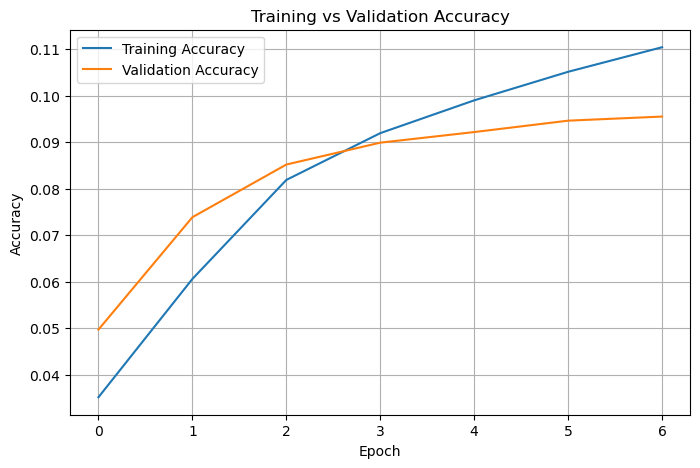

In [18]:
# Plot training and validation accuracy

plt.figure(figsize=(8, 5))

plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')

plt.title('Training vs Validation Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True)

plt.show()

#### Training vs Validation Loss

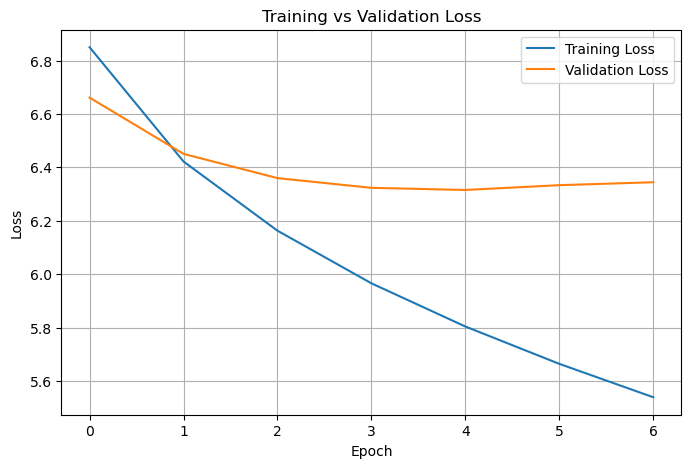

In [19]:
# Plot training and validation loss

plt.figure(figsize=(8, 5))

plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')

plt.title('Training vs Validation Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)

plt.show()

#### Evaluate the Model

In [20]:
# Evaluate the model on validation data

val_loss, val_accuracy = model.evaluate(
    X_val,
    y_val,
    batch_size=64,
    verbose=1
)

print("Validation Loss:", val_loss)
print("Validation Accuracy:", val_accuracy)
print("Validation Accuracy (%):", val_accuracy * 100)

638/638 ━━━━━━━━━━━━━━━━━━━━ 5s 8ms/step - accuracy: 0.0921 - loss: 6.3155
Validation Loss: 6.315464019775391
Validation Accuracy: 0.0921497493982315
Validation Accuracy (%): 9.21497493982315


#### Next Word Prediction Function

In [31]:
def predict_next_word(seed_text):
    # Convert input text into token IDs
    token_list = tokenizer.texts_to_sequences([seed_text])[0]

    # Keep only the last 20 tokens
    token_list = token_list[-20:]

    # Pad sequence
    token_list = pad_sequences(
        [token_list],
        maxlen=20,
        padding='pre'
    )

    # Predict probabilities
    predictions = model.predict(
        token_list,
        verbose=0
    )[0]

    # Get the most probable word
    predicted_index = np.argmax(predictions)

    # Convert token ID to word
    index_to_word = {index: word for word, index in tokenizer.word_index.items()}

    return index_to_word.get(predicted_index, "Unknown")

In [32]:
print("Input: First citizen")
print("Predicted next word:", predict_next_word("First citizen"))

print("\nInput: before we proceed")
print("Predicted next word:", predict_next_word("before we proceed"))

print("\nInput: the king")
print("Predicted next word:", predict_next_word("the king"))

Input: First citizen
Predicted next word: i

Input: before we proceed
Predicted next word: and

Input: the king
Predicted next word: of


#### Generate multiple words

In [23]:
def generate_text(seed_text, next_words=20):
    generated_text = seed_text

    for _ in range(next_words):
        next_word = predict_next_word(generated_text)

        if next_word == "Unknown":
            break

        generated_text += " " + next_word

    return generated_text

In [24]:
print(generate_text("before we proceed", next_words=20))

before we proceed and in the world and the world of the world and the king of york i am not to be


In [25]:
print(generate_text("the king", next_words=20))

the king of york and i have been a man to the world and the king of york i am not to


In [26]:
print(generate_text("first citizen", next_words=20))

first citizen i have been a man to be a man to be a man to be a man to be a


#### Top-K + Temperature Sampling

In [27]:
def generate_text(seed_text, next_words=20, temperature=0.8, top_k=10):
    generated_text = seed_text

    for _ in range(next_words):

        # Convert text to tokens
        token_list = tokenizer.texts_to_sequences([generated_text])[0]

        # Keep last 20 tokens
        token_list = token_list[-20:]

        # Pad sequence
        token_list = pad_sequences(
            [token_list],
            maxlen=20,
            padding='pre'
        )

        # Get probability distribution
        predictions = model.predict(token_list, verbose=0)[0]

        # Apply temperature
        predictions = np.log(predictions + 1e-8) / temperature
        probabilities = np.exp(predictions) / np.sum(np.exp(predictions))

        # Select top-k words
        top_indices = np.argsort(probabilities)[-top_k:]

        top_probabilities = probabilities[top_indices]
        top_probabilities = top_probabilities / np.sum(top_probabilities)

        # Randomly select from top-k
        predicted_index = np.random.choice(
            top_indices,
            p=top_probabilities
        )

        # Convert ID back to word
        predicted_word = None

        for word, index in tokenizer.word_index.items():
            if index == predicted_index:
                predicted_word = word
                break

        if predicted_word is None:
            break

        generated_text += " " + predicted_word

    return generated_text

In [28]:
print(generate_text("first citizen", next_words=20))

first citizen then we would not be a gentleman to make the world to him and a word of his own face


In [29]:
print(generate_text("the king", next_words=20))

the king of gaunt and my tongue will i be done to me and a man of my life my lord is


In [30]:
print(generate_text("before we proceed", next_words=20))

before we proceed for his love i will to make them be gone to be a man in the duke gloucester i must
